# Forecasting next-day yellow-cab demand in Manhattan and at the airports: EDA

**15.071 The AI Edge, Project 1 (Predictive AI).** The project brief asks every project to answer four questions. This notebook covers the data side of each and sets up the modeling work:

| Project 1 question | where it's addressed here |
|---|---|
| (i) *What problem are we solving?* stakeholder, current process, opportunity | **§0 business problem** |
| (ii) *What can AI do?* acquire data, design the solution | **§1–§6**: data, scope, target, patterns, features |
| (iii) *Does it work?* evaluate against benchmarks | **§7**: business-rule baselines vs. a first ML model |
| (iv) *Does it matter?* translate into $ / operations | **§8**: simulated cost of forecast error for the fleet |

The data is `data/model_table.csv.gz`, produced by `build_dataset.py` with its defaults: busy zones only, 24-hour-ahead features.

## 0. The business problem (simulated client)

> **Client (fictional):** *MetroCab Fleet*, a New York City yellow-taxi fleet operating **≈ 1,000 medallion cabs** (about 7% of the city's 13,587 yellow medallions). Its drivers lease cabs by the 12-hour shift.
>
> **Stakeholder:** the **Director of Fleet Operations**. Every afternoon they decide, for tomorrow, **how many cabs to put on the road each hour, and where to stage them**: which Manhattan neighborhoods, and how many cabs to send to the JFK / LaGuardia taxi holding lots.

**Current process (the benchmark).** A rule of thumb: *"tomorrow will look like the same hour last week"*, sometimes averaged over the last four weeks. This is cheap and catches the weekly rhythm, but it misses trends, holidays, and anything unusual.

**Why forecast errors cost money**

| error | what happens | cost |
|---|---|---|
| **Under-forecast** | too few cabs where riders are; riders take Uber/Lyft or the subway | lost fares, lost lease revenue, a worse service reputation |
| **Over-forecast** | cabs circle empty or wait in long airport queues | idle driver hours, fuel, wear; drivers' earnings fall, which drives churn |

**The opportunity.** A model that predicts **pickups per taxi zone per hour, 24 hours ahead**, more accurately than the rule of thumb. That lets the fleet match supply to demand, and §8 turns the accuracy gain into an estimated dollar value.

**Prediction task:** for each of 49 busy zones *z* and hour *t*, forecast `pickups[z, t]` using information available by *t − 24h*.

In [1]:
import pathlib, urllib.request
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import poisson

pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 80, "display.float_format", "{:,.3f}".format)

# Reference palette (dataviz skill): categorical slots in fixed order, recessive axes
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=C),
})
AREA_COLOR = {"Manhattan": C[0], "Airports": C[1]}

DATA = pathlib.Path("data")
TABLE = DATA / "model_table.csv.gz"
DB = DATA / "taxi.duckdb"                 # intermediate tables from build_dataset.py (all 263 zones)
LOOKUP = DATA / "raw" / "taxi_zone_lookup.csv"
FEATURES = (DATA / "model_table.features.txt").read_text().split()
TARGET = "pickups"
AIRPORTS = {132: "JFK Airport", 138: "LaGuardia Airport"}
SCOPE_START, SCOPE_END, THRESHOLD = "2025-01-05", "2025-07-01", 20   # build_dataset.py defaults

df = duckdb.sql(f"SELECT * FROM read_csv_auto('{TABLE}')").df()
for c in ["zone_name", "borough", "split"]:
    df[c] = df[c].astype("category")
df["area"] = np.where(df.zone_id.isin(AIRPORTS), "Airports", "Manhattan")
print(f"{len(df):,} rows x {df.shape[1]} columns, {df.zone_id.nunique()} zones")
df.head()

1,541,736 rows x 24 columns, 49 zones


,zone_id,zone_name,borough,ts_hour,split,pickups,zone_code,borough_code,lag_h,lag_48h,roll_24h,roll_7d,lag_168h,lag_336h,same_hour_4wk,hist_avg,duration_lag_h,fare_lag_h,hr,dow,month,is_weekend,post_cbd_pricing,area
0,13,Battery Park City,Manhattan,2023-01-29,train,3,0,0,8,4,24.250,23.655,6,2,7.000,8.786,189.500,22.450,0,0,1,1,0,Manhattan
1,41,Central Harlem,Manhattan,2023-01-29,train,9,1,0,5,7,11.750,9.827,4,6,9.750,15.908,275.600,17.420,0,0,1,1,0,Manhattan
2,43,Central Park,Manhattan,2023-01-29,train,13,2,0,18,9,80.958,69.589,20,21,38.500,20.237,11.170,23.230,0,0,1,1,0,Manhattan
3,48,Clinton East,Manhattan,2023-01-29,train,255,3,0,238,134,130.708,115.125,272,255,220.750,264.183,12.280,23.260,0,0,1,1,0,Manhattan
4,50,Clinton West,Manhattan,2023-01-29,train,53,4,0,34,11,28.792,25.048,50,42,51.500,51.420,10.590,22.010,0,0,1,1,0,Manhattan


## 1. The data

### 1.1 What is a NYC yellow taxi?
- **Who runs them.** Yellow cabs are licensed and regulated by the **NYC Taxi & Limousine Commission (TLC)**. Every yellow cab needs a **medallion**, a city-issued permit that has been capped since 1937 and today numbers **13,587**. Medallions are owned by individual owner-drivers or by **fleets** and agents, who lease cabs to drivers by the shift. That's the business model of our simulated client.
- **Where they work.** Yellow cabs are the only vehicles allowed to pick up **street hails** (a raised arm) anywhere in the five boroughs. In practice they concentrate in **Manhattan** and the **airport taxi lines at JFK and LaGuardia**.
  - Since 2013, green **"Boro Taxis"** serve street hails in upper Manhattan and the outer boroughs. They may *not* pick up in Manhattan below E 96th / W 110th St or at the airports.
  - App-based **for-hire vehicles** (Uber, Lyft) can only take pre-arranged trips. They are yellow cabs' main competitor.
- **How riders get one:** street hail, airport dispatcher lines, or e-hail apps (Curb, and more recently yellow cabs listed inside the Uber and Lyft apps).
- **Pricing:** metered fare plus surcharges, including the MTA congestion surcharge, airport fees, and since **2025-01-05** a per-trip **congestion-pricing toll** for trips in the Manhattan Central Business District.

### 1.2 Where the data comes from
- **TLC Trip Record Data** (public): one row per completed yellow-cab trip, recorded automatically by each cab's meter/GPS system (the TLC's *Taxicab Passenger Enhancement Program*, TPEP). It's published monthly as Parquet files, about 2 months after the month ends.
  - Source: `https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_YYYY-MM.parquet`, plus the taxi-zone lookup table and zone shapefile.
- **Fields used:** pickup and dropoff time, pickup zone (`PULocationID`), trip distance, and total amount charged. The data has **no personal information**: locations are recorded only as one of 263 taxi zones (TLC neighborhood polygons), never as GPS points.
- **Coverage:** **January 2023 → August 2026** (44 monthly files, ≈ 157 million trips).
- **What the target measures.** `pickups` counts *completed* trips. That's **served demand**: riders who couldn't find a cab aren't recorded. In the busy zones studied here, cab supply is usually plentiful, so served demand is a reasonable stand-in for real demand.

### 1.3 How the modeling table is built (`build_dataset.py`)
1. Download the monthly trip files and the zone lookup.
2. Count trips per **pickup zone × hour** with DuckDB. Drop impossible records (negative durations, unknown zones 264/265).
3. Fill in a **dense** zone × hour grid, so hours with no trips appear as 0.
4. **Keep busy zones only:** zones averaging **≥ 20 pickups/h** over 2025-01-05 → 2025-06-30 (`--min-avg 20 --min-avg-since 2025-01-05`). §2 explains this choice.
5. Build features that use only information available **24 hours before** the target hour (`--horizon 24`). Split by time into **train / val / test**.

raw yellow-cab trips in 2023-01 → 2026-08 (zones 1–263): 157,215,154  (≈ 3.6M per month)


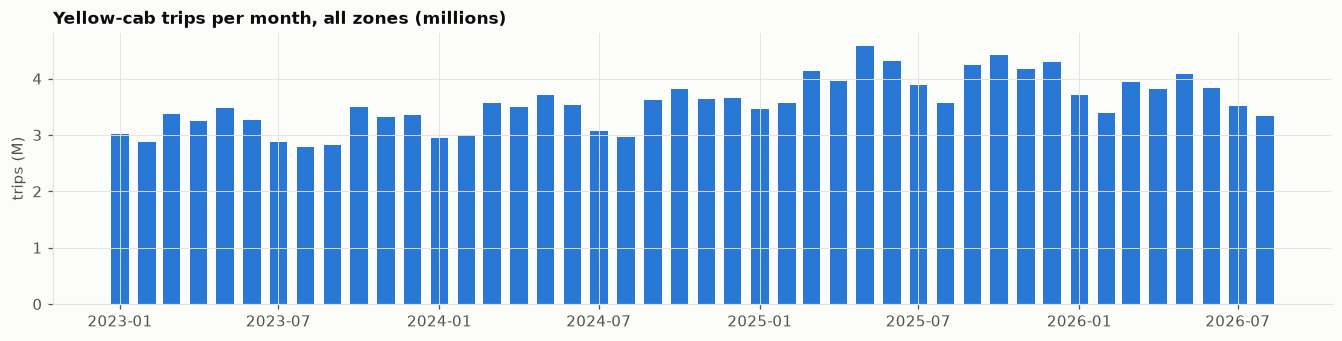

In [2]:
raw = duckdb.connect(str(DB), read_only=True)
months = raw.sql("SELECT date_trunc('month', ts_hour) AS month, SUM(pickups) AS trips FROM zone_hour GROUP BY 1 ORDER BY 1").df()
print(f"raw yellow-cab trips in 2023-01 → 2026-08 (zones 1–263): {months.trips.sum():,.0f}  "
      f"(≈ {months.trips.mean() / 1e6:.1f}M per month)")

fig, ax = plt.subplots(figsize=(15, 3.2))
ax.bar(months.month, months.trips / 1e6, width=20, color=C[0])
ax.set_title("Yellow-cab trips per month, all zones (millions)"); ax.set_ylabel("trips (M)")
plt.show()

## 2. Scope: which zones, and why only the busy ones

NYC has 263 taxi zones, but yellow-cab activity is extremely concentrated. Forecasting a zone that averages 2 trips an hour is mostly forecasting **randomness**. For a count with expected value μ, even a *perfect* forecast misses by about E|Y − μ| / μ (the Poisson noise floor). That's about 50% of volume at μ = 2/h, about 18% at 20/h, and about 8% at 100/h. It's also not where the fleet's money is. So the table keeps only zones averaging **≥ 20 pickups/h** in the most recent training months (2025-01-05 → 06-30, after congestion pricing started). This selection uses training data only, so it can't leak information from val/test.

In [3]:
lookup = pd.read_csv(LOOKUP)
zall = raw.sql(f"""
    SELECT zone_id, any_value(zone_name) AS zone_name, any_value(borough) AS borough,
           AVG(pickups) FILTER (WHERE ts_hour >= '{SCOPE_START}' AND ts_hour < '{SCOPE_END}') AS mean_recent,
           AVG(pickups) FILTER (WHERE ts_hour >= '2025-07-01' AND ts_hour < '2026-01-01') AS mean_val,
           AVG(pickups) FILTER (WHERE ts_hour >= '2026-01-01') AS mean_test,
           SUM(pickups) AS total_pickups
    FROM panel GROUP BY zone_id""").df().set_index("zone_id")
zall["kept"] = zall.index.isin(df.zone_id.unique())

def noise_floor(mu):
    # E|Y - mu| / mu for Y ~ Poisson(mu): the WAPE a perfect forecast would still have
    k = np.arange(0, int(mu * 4 + 50))
    return (np.abs(k - mu) * poisson.pmf(k, mu)).sum() / mu

rows = []
for thr in [1, 5, 10, 20, 50, 100]:
    k = zall[zall.mean_recent >= thr]
    rows.append({"threshold (pickups/h)": thr, "zones kept": len(k),
                 "share of all pickups": k.total_pickups.sum() / zall.total_pickups.sum(),
                 "Manhattan / Queens / other": f"{(k.borough == 'Manhattan').sum()} / {(k.borough == 'Queens').sum()} / {(~k.borough.isin(['Manhattan', 'Queens'])).sum()}",
                 "noise floor at threshold": noise_floor(thr),
                 "min zone mean in val": k.mean_val.min(), "min zone mean in test": k.mean_test.min()})
pd.DataFrame(rows).set_index("threshold (pickups/h)")

,zones kept,share of all pickups,Manhattan / Queens / other,noise floor at threshold,min zone mean in val,min zone mean in test
threshold (pickups/h),,,,,,
1,154,0.994,61 / 34 / 59,0.736,1.032,0.757
5,83,0.974,58 / 8 / 17,0.351,5.941,4.130
10,63,0.957,56 / 6 / 1,0.250,10.498,9.151
20,49,0.927,47 / 2 / 0,0.178,23.207,22.193
50,38,0.862,36 / 2 / 0,0.113,55.218,50.269
100,23,0.660,21 / 2 / 0,0.080,97.678,94.629


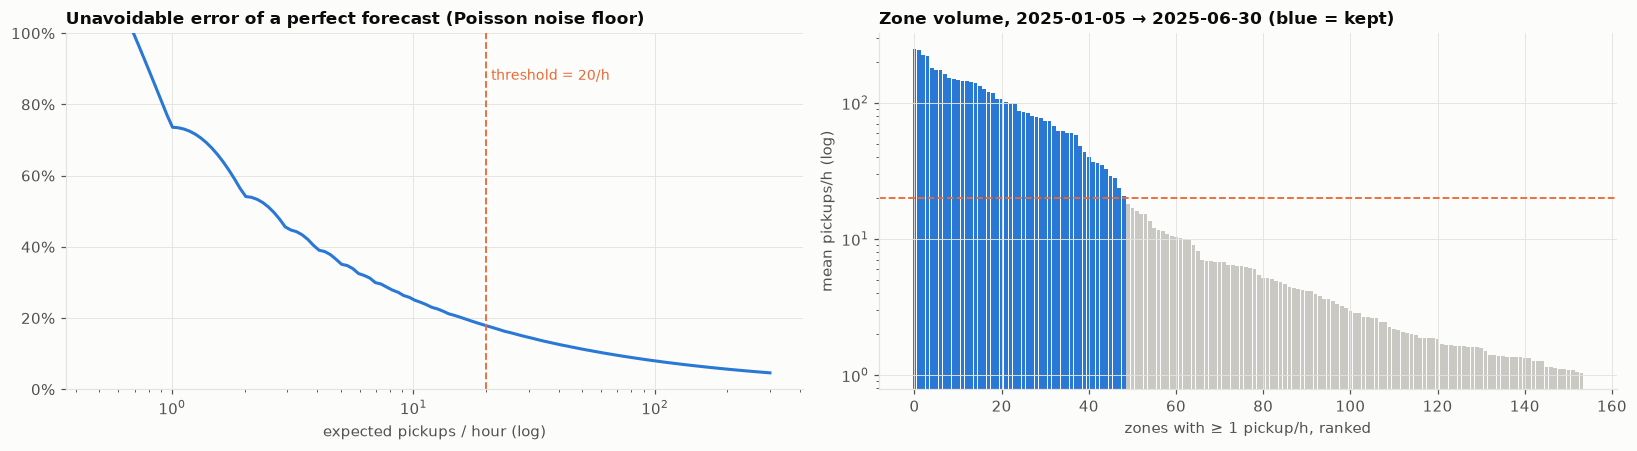

Zones around the cutoff:


,zone_name,borough,mean_recent,mean_val,mean_test,kept
zone_id,,,,,,
232,Two Bridges/Seward Park,Manhattan,13.565,16.770,16.784,False
42,Central Harlem North,Manhattan,15.151,18.494,18.621,False
24,Bloomingdale,Manhattan,15.195,15.728,16.137,False
70,East Elmhurst,Queens,16.114,14.936,10.884,False
4,Alphabet City,Manhattan,16.795,19.443,22.374,False
88,Financial District South,Manhattan,18.196,21.481,19.078,False
74,East Harlem North,Manhattan,20.573,23.207,22.193,True
41,Central Harlem,Manhattan,23.761,25.451,25.654,True
261,World Trade Center,Manhattan,28.082,29.502,22.919,True


In [4]:
mus = np.logspace(np.log10(0.5), np.log10(300), 120)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
ax.plot(mus, [noise_floor(m) for m in mus], color=C[0])
ax.axvline(THRESHOLD, color=C[1], linestyle="--", linewidth=1.2)
ax.text(THRESHOLD * 1.05, 0.9, f"threshold = {THRESHOLD}/h", color=C[1], fontsize=9, va="top")
ax.set_xscale("log"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, 1)
ax.set_xlabel("expected pickups / hour (log)"); ax.set_title("Unavoidable error of a perfect forecast (Poisson noise floor)")

ax = axes[1]
s = zall.mean_recent[zall.mean_recent >= 1].sort_values(ascending=False).reset_index(drop=True)
ax.bar(s.index, s.values, color=[C[0] if v >= THRESHOLD else "#c9c8c2" for v in s.values], width=0.85)
ax.axhline(THRESHOLD, color=C[1], linestyle="--", linewidth=1.2)
ax.set_yscale("log"); ax.set_xlabel("zones with ≥ 1 pickup/h, ranked"); ax.set_ylabel("mean pickups/h (log)")
ax.set_title(f"Zone volume, {SCOPE_START} → 2025-06-30 (blue = kept)")
plt.tight_layout(); plt.show()

print("Zones around the cutoff:")
zall[(zall.mean_recent >= 12) & (zall.mean_recent < 30)].sort_values("mean_recent")[
    ["zone_name", "borough", "mean_recent", "mean_val", "mean_test", "kept"]]

**Why 20/h**
- **Natural gap:** no zone falls between 18.2 (Financial District South) and 20.6 (East Harlem North).
- **Stable out of sample:** every kept zone averages ≥ 22/h in both val and test.
- **Almost all the business:** **49 zones** (47 in Manhattan plus **JFK** and **LaGuardia**) carry **≈ 93%** of all yellow-cab pickups citywide.
- **Small noise:** the noise floor at the cutoff is about 18%, vs. 20–60% in the dropped zones.
- **Why not stricter:** 50/h would drop the fast-growing upper-Manhattan and Lower East Side zones.

**Map of the scope.** Blue = the 49 modeled zones, shaded by volume. Grey = zones with yellow-cab activity that are out of scope. Pale = near-zero yellow-cab activity.

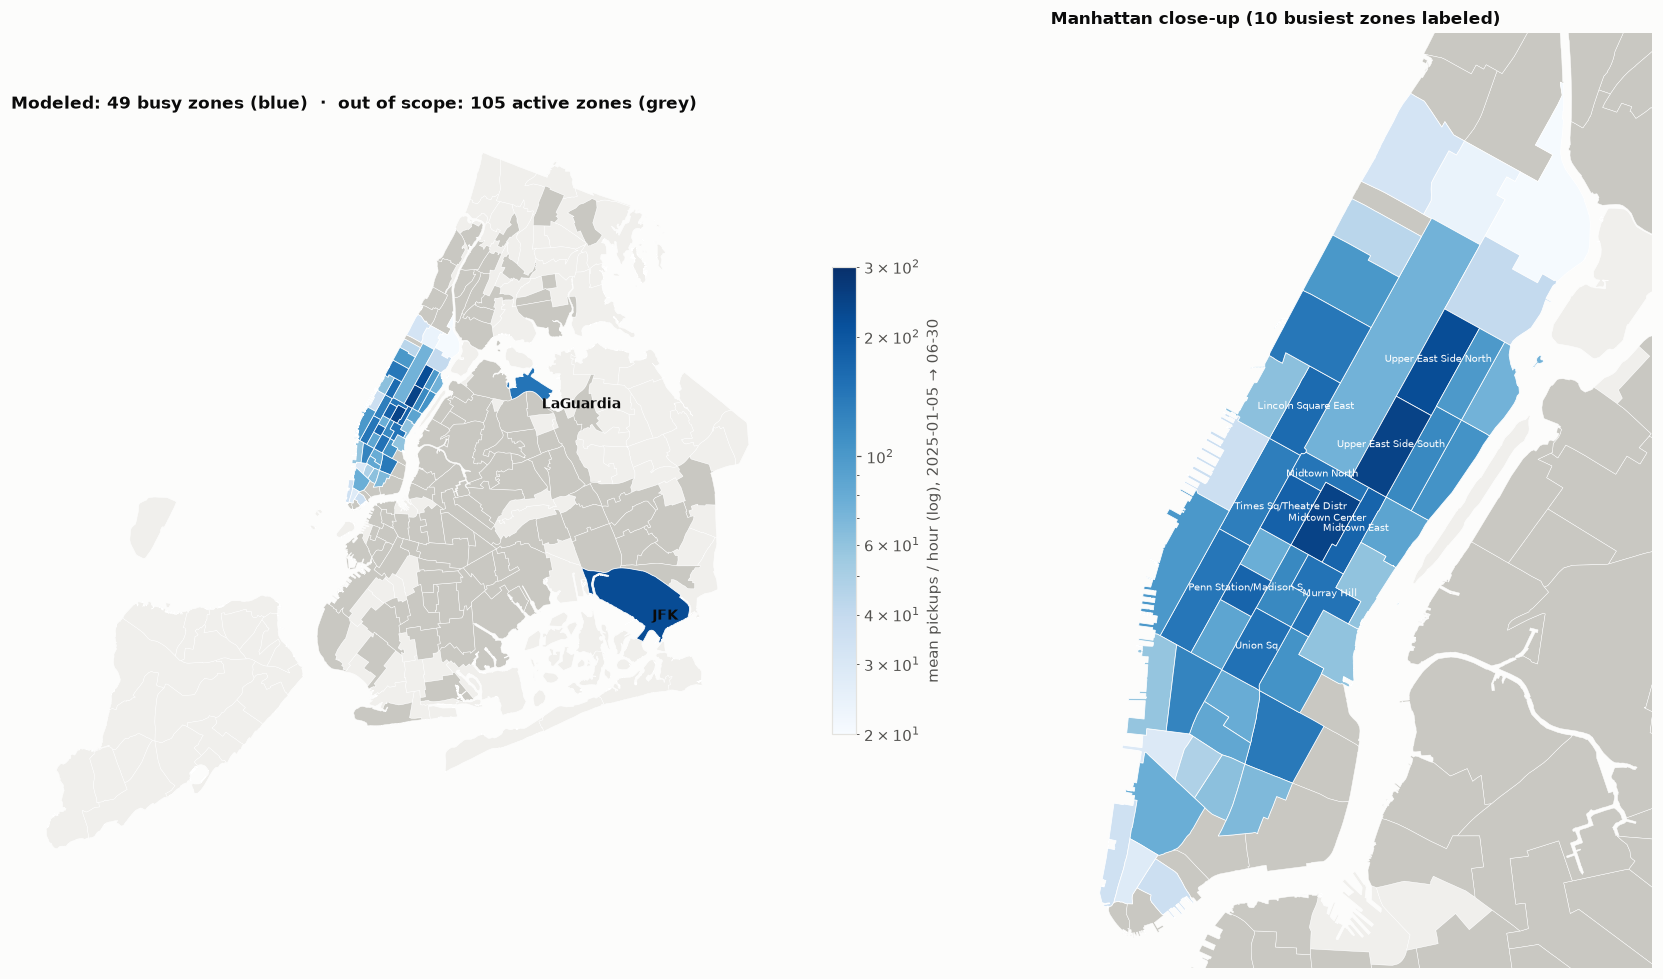

In [5]:
core = zall[zall.kept]
try:
    import geopandas as gpd
    shp_zip = DATA / "raw" / "taxi_zones.zip"
    if not shp_zip.exists():
        urllib.request.urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip", shp_zip)
    zones = gpd.read_file(f"zip://{shp_zip.resolve()}!taxi_zones/taxi_zones.shp").dissolve(by="LocationID", as_index=False)
    zones = zones.merge(zall[["mean_recent", "kept"]], left_on="LocationID", right_index=True, how="left")
    zones["status"] = np.where(zones.kept == True, "core", np.where(zones.mean_recent >= 1, "dropped", "absent"))

    fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1.25, 1]})
    norm = plt.matplotlib.colors.LogNorm(vmin=THRESHOLD, vmax=300)
    for ax in axes:
        zones[zones.status == "absent"].plot(ax=ax, color="#f0efec", edgecolor="white", linewidth=0.3)
        zones[zones.status == "dropped"].plot(ax=ax, color="#c9c8c2", edgecolor="white", linewidth=0.3)
        zones[zones.status == "core"].plot(ax=ax, column="mean_recent", cmap="Blues", norm=norm, edgecolor="white", linewidth=0.5)
        ax.set_axis_off()
    fig.colorbar(plt.cm.ScalarMappable(cmap="Blues", norm=norm), ax=axes[0], shrink=0.5,
                 label=f"mean pickups / hour (log), {SCOPE_START} → 06-30")
    for zid, name in AIRPORTS.items():
        c = zones[zones.LocationID == zid].geometry.centroid.iloc[0]
        axes[0].annotate(name.replace(" Airport", ""), (c.x, c.y), xytext=(8, -14), textcoords="offset points",
                         fontsize=9, color=INK, weight="bold")
    axes[0].set_title(f"Modeled: {len(core)} busy zones (blue)  ·  out of scope: {(zones.status == 'dropped').sum()} active zones (grey)")

    man = zones[(zones.status == "core") & ~zones.LocationID.isin(AIRPORTS)]
    x0, y0, x1, y1 = man.total_bounds
    axes[1].set_xlim(x0 - 2500, x1 + 2500); axes[1].set_ylim(y0 - 2500, y1 + 2500)
    for _, r in man.nlargest(10, "mean_recent").iterrows():
        c = r.geometry.representative_point()
        axes[1].annotate(r.zone[:22], (c.x, c.y), fontsize=6.5, ha="center", color="white" if r.mean_recent > 120 else INK)
    axes[1].set_title("Manhattan close-up (10 busiest zones labeled)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Map skipped:", e)

In [6]:
zone_list = (df.groupby(["zone_id", "zone_name", "area"], observed=True)[TARGET].mean()
               .rename("mean_pickups_all_years").reset_index()
               .merge(core[["mean_recent"]], left_on="zone_id", right_index=True)
               .sort_values("mean_recent", ascending=False, ignore_index=True))
zone_list.to_csv(DATA / "core_zones.csv", index=False)
print(f"{len(zone_list)} modeled zones (saved to data/core_zones.csv); share of pickups by area:")
print(df.groupby("area")[TARGET].sum().div(df[TARGET].sum()).round(3).to_string())
zone_list

49 modeled zones (saved to data/core_zones.csv); share of pickups by area:
area
Airports    0.081
Manhattan   0.919


,zone_id,zone_name,area,mean_pickups_all_years,mean_recent
0,237,Upper East Side South,Manhattan,222.639,247.290
1,161,Midtown Center,Manhattan,218.351,246.016
2,132,JFK Airport,Airports,225.027,224.642
3,236,Upper East Side North,Manhattan,198.432,222.463
4,230,Times Sq/Theatre District,Manhattan,157.017,179.734
5,186,Penn Station/Madison Sq West,Manhattan,159.387,173.882
6,162,Midtown East,Manhattan,161.681,173.613
7,142,Lincoln Square East,Manhattan,149.838,162.200
8,234,Union Sq,Manhattan,130.818,151.519
9,170,Murray Hill,Manhattan,136.616,149.217


## 3. Size and timeframe

In [7]:
n_hours = df.ts_hour.nunique()
n_zones = df.zone_id.nunique()
print(f"rows:           {len(df):,}")
print(f"zones:          {n_zones}")
print(f"hours:          {n_hours:,}  ({df.ts_hour.min()} -> {df.ts_hour.max()}, {n_hours / 24:,.0f} days)")
print(f"zone x hour:    {n_zones * n_hours:,}  (dense panel: {n_zones * n_hours == len(df)})")
print(f"duplicate keys: {df.duplicated(['zone_id', 'ts_hour']).sum()}")
print(f"total pickups:  {df[TARGET].sum():,}")
expected = pd.date_range(df.ts_hour.min(), df.ts_hour.max(), freq="h")
print(f"missing hours in the timeline: {len(expected.difference(df.ts_hour.unique()))}")

rows:           1,541,736
zones:          49
hours:          31,464  (2023-01-29 00:00:00 -> 2026-08-31 23:00:00, 1,311 days)
zone x hour:    1,541,736  (dense panel: True)
duplicate keys: 0
total pickups:  143,081,747
missing hours in the timeline: 0


- **About 1.54M rows:** 49 zones × 31,464 hours (2023-01-29 → 2026-08-31, about 3.6 years).
- The table starts **2023-01-29**, not 01-01, because the first 4 weeks are used as warm-up for the 4-week lag features.
- The panel is **dense**: every zone has a row for every hour (true zeros included), with no duplicates and no gaps in the timeline.

## 4. Train / validation / test split

In [8]:
split = (df.groupby("split", observed=True)
           .agg(rows=(TARGET, "size"), first=("ts_hour", "min"), last=("ts_hour", "max"),
                mean_pickups=(TARGET, "mean"), zero_frac=(TARGET, lambda s: (s == 0).mean()))
           .sort_values("first"))
split["share_rows"] = split.rows / split.rows.sum()
split["months"] = ((split["last"] - split["first"]).dt.days / 30.4).round(1)
split

,rows,first,last,mean_pickups,zero_frac,share_rows,months
split,,,,,,,
train,1039584,2023-01-29,2025-06-30 23:00:00,90.921,0.015,0.674,29.000
val,216384,2025-07-01,2025-12-31 23:00:00,101.465,0.006,0.140,6.000
test,285768,2026-01-01,2026-08-31 23:00:00,93.104,0.008,0.185,8.000


The split is **by time**, as a forecasting problem requires. A random split would leak future information through the lag features and the autocorrelation between neighboring hours.

| split | period | share | use |
|---|---|---|---|
| train | 2023-01-29 → 2025-06-30 (29 mo) | 67% | fit models |
| val | 2025-07-01 → 2025-12-31 (6 mo) | 14% | choose models / tune |
| test | 2026-01-01 → 2026-08-31 (8 mo) | 19% | final, one-time evaluation |

**Recommendations**
1. Tune on val, then **refit on train+val** and score test once. When refitting, rebuild with `--train-end 2026-01-01` so `hist_avg` uses train+val too.
2. **Val (Jul–Dec) and test (Jan–Aug) cover different seasons.** For a robust estimate, add **rolling-origin backtests**: train through month *m*, score month *m+1*, repeated over the last 12 months.
3. No gap between splits is needed: every feature is ≥ 24h old, which matches how the forecast would be used in practice.

## 5. The target: pickups per zone-hour

In [9]:
y = df[TARGET]
desc = y.describe(percentiles=[.01, .1, .25, .5, .75, .9, .99, .999]).to_frame().T
desc["var"] = y.var(); desc["var/mean"] = y.var() / y.mean(); desc["zero_frac"] = (y == 0).mean()
desc

,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,99.9%,max,var,var/mean,zero_frac
pickups,"1,541,736.000",92.806,98.135,0.000,0.000,6.000,20.000,61.000,134.000,219.000,448.000,638.000,"1,167.000","9,630.437",103.770,0.013


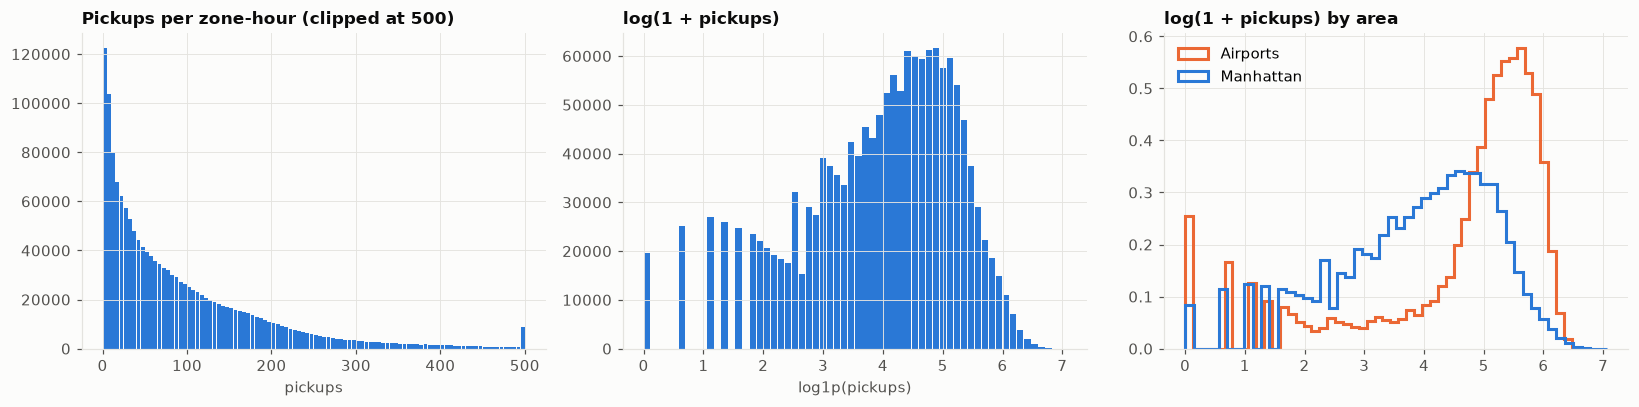

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(y.clip(upper=500), bins=100, color=C[0], rwidth=0.9)
axes[0].set_title("Pickups per zone-hour (clipped at 500)"); axes[0].set_xlabel("pickups")
axes[1].hist(np.log1p(y), bins=60, color=C[0], rwidth=0.9)
axes[1].set_title("log(1 + pickups)"); axes[1].set_xlabel("log1p(pickups)")
for a, g in df.groupby("area"):
    axes[2].hist(np.log1p(g[TARGET]), bins=50, histtype="step", density=True, linewidth=2, color=AREA_COLOR[a], label=a)
axes[2].set_title("log(1 + pickups) by area"); axes[2].legend()
plt.tight_layout(); plt.show()

In [11]:
by_a = df.groupby(["area", "split"], observed=True)[TARGET].agg(
    mean="mean", median="median", zero_frac=lambda s: (s == 0).mean()).unstack("split")
display(by_a.round(3))
zone_dist = (df.groupby("zone_name", observed=True)[TARGET]
               .agg(mean="mean", median="median", p99=lambda s: s.quantile(.99), zero_frac=lambda s: (s == 0).mean())
               .sort_values("mean", ascending=False))
print("Busiest and quietest modeled zones:")
pd.concat([zone_dist.head(6), zone_dist.tail(6)])

mean                  median                 zero_frac            
split        test   train     val    test   train     val      test train   val
area                                                                           
Airports  164.793 187.752 197.379 155.000 182.000 183.000     0.034 0.034 0.031
Manhattan  90.053  86.801  97.383  62.000  56.000  67.000     0.007 0.014 0.005

Busiest and quietest modeled zones:


,mean,median,p99,zero_frac
zone_name,,,,
JFK Airport,225.027,207.000,539.000,0.002
Upper East Side South,222.639,225.000,602.000,0.004
Midtown Center,218.351,197.000,698.000,0.001
Upper East Side North,198.432,190.000,550.370,0.011
Midtown East,161.681,163.000,483.000,0.001
Penn Station/Madison Sq West,159.387,174.000,361.370,0.001
Battery Park City,30.500,27.000,111.000,0.078
Morningside Heights,26.418,25.000,90.000,0.026
World Trade Center,25.126,21.000,76.000,0.042


**Takeaways**
- **Non-negative integer counts**, median ≈ 60 and mean ≈ 93 per zone-hour, with a long right tail (99th pct ≈ 450, max 1,167).
- **Zeros are rare (≈ 1%).** They are mostly overnight hours in the smaller zones, plus data artifacts (§6). Zero-inflation isn't a concern.
- **The airports behave differently:** higher volume (median ≈ 180/h) and a more symmetric distribution. Manhattan zones range from about 16 to 220/h on average, so volume varies more than 10× across modeled zones. Metrics need to account for that (§7).

## 6. Patterns over time

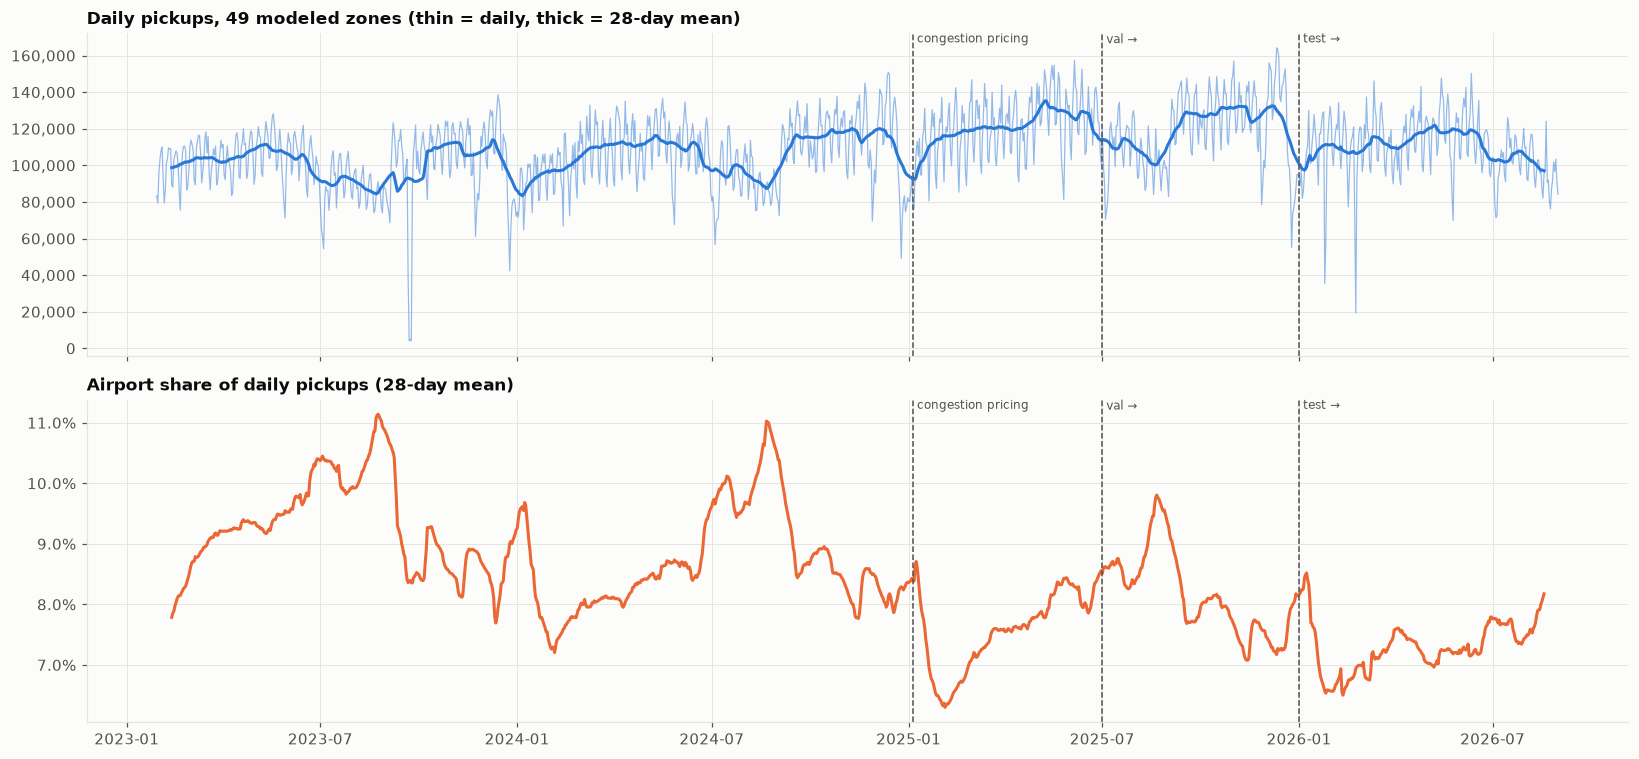

In [12]:
daily = df.groupby([df.ts_hour.dt.floor("D"), "area"])[TARGET].sum().unstack()
tot = daily.sum(axis=1)
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
axes[0].plot(tot.index, tot, color=C[0], linewidth=0.8, alpha=0.5)
axes[0].plot(tot.index, tot.rolling(28, center=True).mean(), color=C[0])
axes[0].set_title("Daily pickups, 49 modeled zones (thin = daily, thick = 28-day mean)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
share = (daily["Airports"] / tot).rolling(28, center=True).mean()
axes[1].plot(share.index, share, color=AREA_COLOR["Airports"])
axes[1].set_title("Airport share of daily pickups (28-day mean)"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
for ax in axes:
    for d, lab in [("2025-07-01", "val →"), ("2026-01-01", "test →"), ("2025-01-05", "congestion pricing")]:
        ax.axvline(pd.Timestamp(d), color=INK2, linestyle="--", linewidth=1)
        ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + lab, color=INK2, va="top", fontsize=8)
plt.tight_layout(); plt.show()

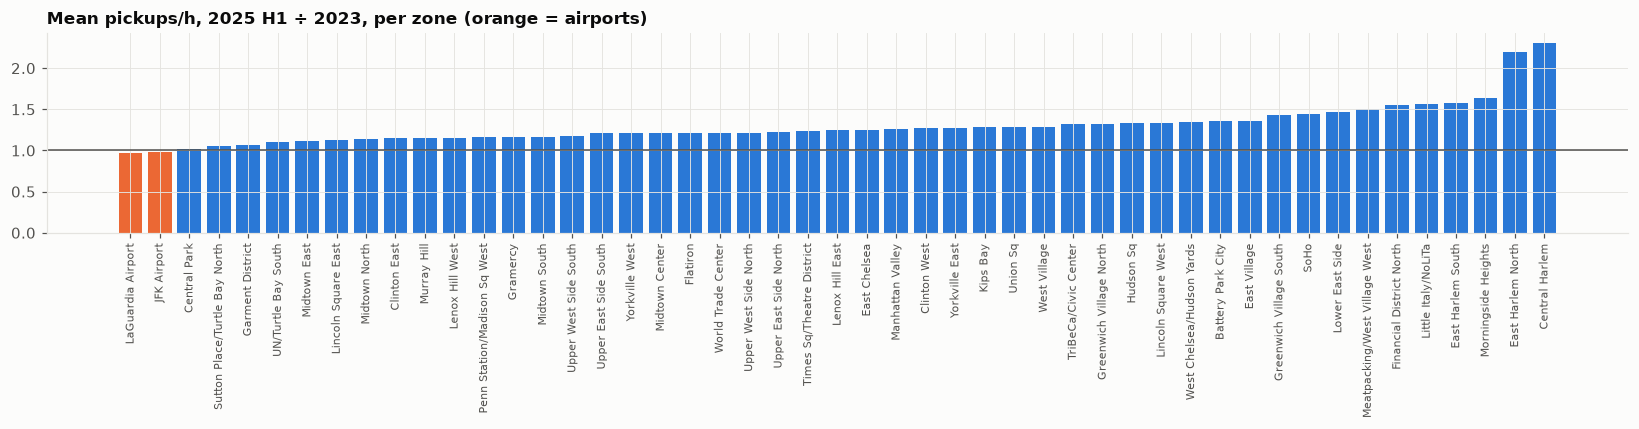

Biggest growers:


,2023,2024,2025H1,val,test,2025H1 / 2023
zone_name,,,,,,
Central Harlem,10.287,13.631,23.761,25.451,25.654,2.310
East Harlem North,9.366,12.272,20.573,23.207,22.193,2.197
Morningside Heights,19.813,22.749,32.407,32.416,32.421,1.636
East Harlem South,25.314,30.023,39.915,42.469,41.786,1.577
Little Italy/NoLiTa,39.849,48.364,62.285,62.827,56.049,1.563
Financial District North,23.576,26.804,36.511,42.384,36.773,1.549
Meatpacking/West Village West,38.999,47.305,58.473,55.218,50.269,1.499
Lower East Side,46.131,51.337,67.828,70.336,68.616,1.470


ts_hour,2023,2024,2025,2026
mean_per_zone_hour,85.363,90.374,101.917,93.104


In [13]:
growth = (df.groupby("zone_name", observed=True)
            .apply(lambda g: pd.Series({
                "2023": g.loc[g.ts_hour < "2024-01-01", TARGET].mean(),
                "2024": g.loc[(g.ts_hour >= "2024-01-01") & (g.ts_hour < "2025-01-01"), TARGET].mean(),
                "2025H1": g.loc[(g.ts_hour >= SCOPE_START) & (g.ts_hour < SCOPE_END), TARGET].mean(),
                "val": g.loc[g.split == "val", TARGET].mean(),
                "test": g.loc[g.split == "test", TARGET].mean()}), include_groups=False))
growth["2025H1 / 2023"] = growth["2025H1"] / growth["2023"]
growth = growth.sort_values("2025H1 / 2023")
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(range(len(growth)), growth["2025H1 / 2023"], width=0.8,
       color=[C[1] if n in AIRPORTS.values() else C[0] for n in growth.index])
ax.axhline(1, color=INK2, linewidth=1)
ax.set_xticks(range(len(growth)), growth.index, rotation=90, fontsize=7)
ax.set_title("Mean pickups/h, 2025 H1 ÷ 2023, per zone (orange = airports)")
plt.tight_layout(); plt.show()
print("Biggest growers:")
display(growth.sort_values("2025H1 / 2023", ascending=False).head(8))
df.groupby(df.ts_hour.dt.year)[TARGET].agg(mean_per_zone_hour="mean").T

**Trend / regime shift.** Volume per zone-hour rose from ≈ 85 (2023) to ≈ 102 (2025), then eased to ≈ 93 in 2026 (Jan–Aug only, so partly seasonal). The growth was **uneven**: upper Manhattan (Central/East Harlem, Morningside Heights) and downtown nightlife zones grew **≈ 1.4–2.3×**, while Midtown and the airports changed much less. The cause isn't visible in the data; candidates include yellow cabs appearing in the Uber/Lyft apps, fleet changes, and congestion pricing reshaping trips. **Implications:** demand levels are non-stationary, so long-run averages (`hist_avg`) lag behind. Recent lags and recency-weighted training matter.

In [14]:
day = df.groupby(df.ts_hour.dt.floor("D"))[TARGET].sum()
low = day.nsmallest(10).to_frame("pickups")
low["vs. same weekday ±1wk"] = low.pickups / ((day.shift(7) + day.shift(-7)) / 2).reindex(low.index)
low

,pickups,vs. same weekday ±1wk
ts_hour,,
2023-09-22,4030,0.039
2023-09-24,4181,0.045
2023-09-23,4959,0.046
2026-02-23,19326,0.216
2026-01-25,35365,0.337
2023-09-21,39364,0.326
2023-12-25,42359,0.494
2024-12-25,49192,0.460
2023-07-04,54322,0.533


**Unusual days**
- **2023-09-21 → 09-24: missing source data.** These days have about 4–5% of normal volume, and the panel records them as 0 pickups. That's not real demand, and it also corrupts the lag features for the following 4 weeks. **Drop these days (2023-09-21 → 10-22) from training.**
- The other low days are real: **holidays** (Christmas, July 4) and likely **weather** (2026-01-25, 2026-02-23). The current features don't capture either, which is a clear opportunity for future features.

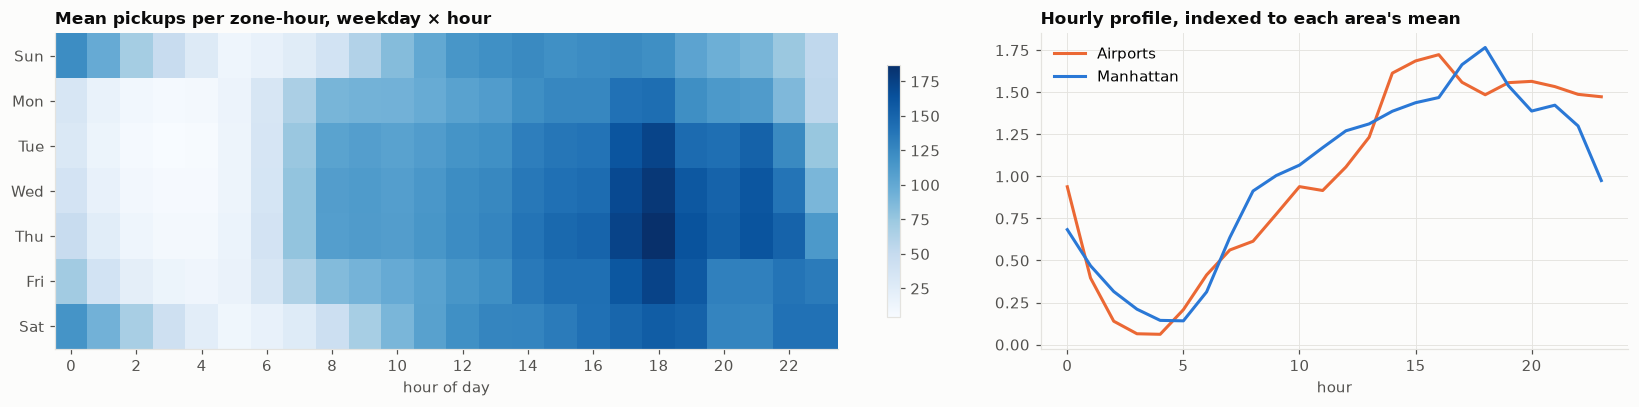

In [15]:
hm = df.groupby(["dow", "hr"])[TARGET].mean().unstack()
hm.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 1.2]})
im = axes[0].imshow(hm.values, aspect="auto", cmap="Blues")
axes[0].set_yticks(range(7), hm.index); axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("hour of day")
axes[0].set_title("Mean pickups per zone-hour, weekday × hour"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
hr_a = df.groupby(["hr", "area"])[TARGET].mean().unstack()
hr_a = hr_a / hr_a.mean()
for a in hr_a:
    axes[1].plot(hr_a.index, hr_a[a], color=AREA_COLOR[a], label=a)
axes[1].set_title("Hourly profile, indexed to each area's mean"); axes[1].set_xlabel("hour"); axes[1].legend()
plt.tight_layout(); plt.show()

- **Strong weekly × hourly rhythm:** a deep trough at 3–5am, a build through the day, and a weekday peak at **17–19h** (Tue–Thu strongest). Friday and Saturday nights stay busy past midnight.
- **The airports run on flight schedules,** not commutes: they peak at **15–16h** and stay high late into the evening.
- The rhythm differs by zone, so the model needs zone × hour × weekday interactions. That's natural for tree models and is what `hist_avg` encodes.

In [16]:
dst = df.groupby("ts_hour")[TARGET].sum()
spring = [pd.Timestamp(f"{y}-{md} 02:00") for y, md in [(2023, "03-12"), (2024, "03-10"), (2025, "03-09"), (2026, "03-08")]]
fall = [pd.Timestamp(f"{y}-{md} 01:00") for y, md in [(2023, "11-05"), (2024, "11-03"), (2025, "11-02")]]
print("Spring-forward 02:00 (hour doesn't exist):", [int(dst.get(t, -1)) for t in spring])
print("Fall-back 01:00 (hour happens twice):    ", [int(dst.get(t, -1)) for t in fall],
      " vs. same hour 1 week earlier:", [int(dst.get(t - pd.Timedelta("7D"), -1)) for t in fall])

Spring-forward 02:00 (hour doesn't exist): [0, 0, 0, 0]
Fall-back 01:00 (hour happens twice):     [7266, 8124, 8874]  vs. same hour 1 week earlier: [5512, 5952, 6316]


**Daylight saving time.** Timestamps are local clock time. The spring-forward 02:00 hour has 0 pickups, and the fall-back 01:00 hour holds two real hours (≈ 1.4× normal). It's only a few rows a year; flag or exclude them in evaluation.

## 7. Features and a first look at modeling

### 7.1 Features
All 17 features use only information available **≥ 24 hours before** the target hour.

| group | features | description |
|---|---|---|
| location | `zone_code` (0–48), `borough_code` (0 = Manhattan, 1 = Queens, i.e. the airports) | categorical. `borough_code` is effectively an `is_airport` flag |
| recent demand | `lag_h` (24h ago), `lag_48h`, `roll_24h`, `roll_7d` | rolling windows end 24h before the target |
| weekly pattern | `lag_168h`, `lag_336h`, `same_hour_4wk` | same hour 1 and 2 weeks ago; average of the same hour over 4 weeks |
| profile | `hist_avg` | zone × weekday × hour average over the training period |
| trip context | `duration_lag_h`, `fare_lag_h` | average trip minutes / $ for pickups 24h earlier. NaN if no trips |
| calendar | `hr`, `dow` (0 = Sun), `month`, `is_weekend` | |
| policy | `post_cbd_pricing` | 1 from 2025-01-05 (congestion pricing) |

In [17]:
num = df[FEATURES].describe(percentiles=[.01, .5, .99]).T
num["missing_frac"] = df[FEATURES].isna().mean()
num["n_unique"] = df[FEATURES].nunique()
num

,count,mean,std,min,1%,50%,99%,max,missing_frac,n_unique
zone_code,"1,541,736.000",24.000,14.142,0.000,0.000,24.000,48.000,48.000,0.000,49
borough_code,"1,541,736.000",0.041,0.198,0.000,0.000,0.000,1.000,1.000,0.000,2
lag_h,"1,541,736.000",92.820,98.142,0.000,0.000,61.000,448.000,"1,167.000",0.000,902
lag_48h,"1,541,736.000",92.830,98.147,0.000,0.000,61.000,448.000,"1,167.000",0.000,902
roll_24h,"1,541,736.000",92.831,62.309,0.125,9.458,80.083,285.167,416.750,0.000,8764
roll_7d,"1,541,736.000",92.836,57.653,4.583,10.530,81.310,255.643,334.387,0.000,48037
lag_168h,"1,541,736.000",92.832,98.192,0.000,0.000,61.000,448.000,"1,167.000",0.000,902
lag_336h,"1,541,736.000",92.852,98.226,0.000,0.000,61.000,448.000,"1,167.000",0.000,902
same_hour_4wk,"1,541,736.000",92.829,95.212,0.000,1.000,63.000,432.250,965.250,0.000,3052
hist_avg,"1,541,736.000",90.619,91.820,0.192,1.308,60.869,408.718,608.015,0.000,7354


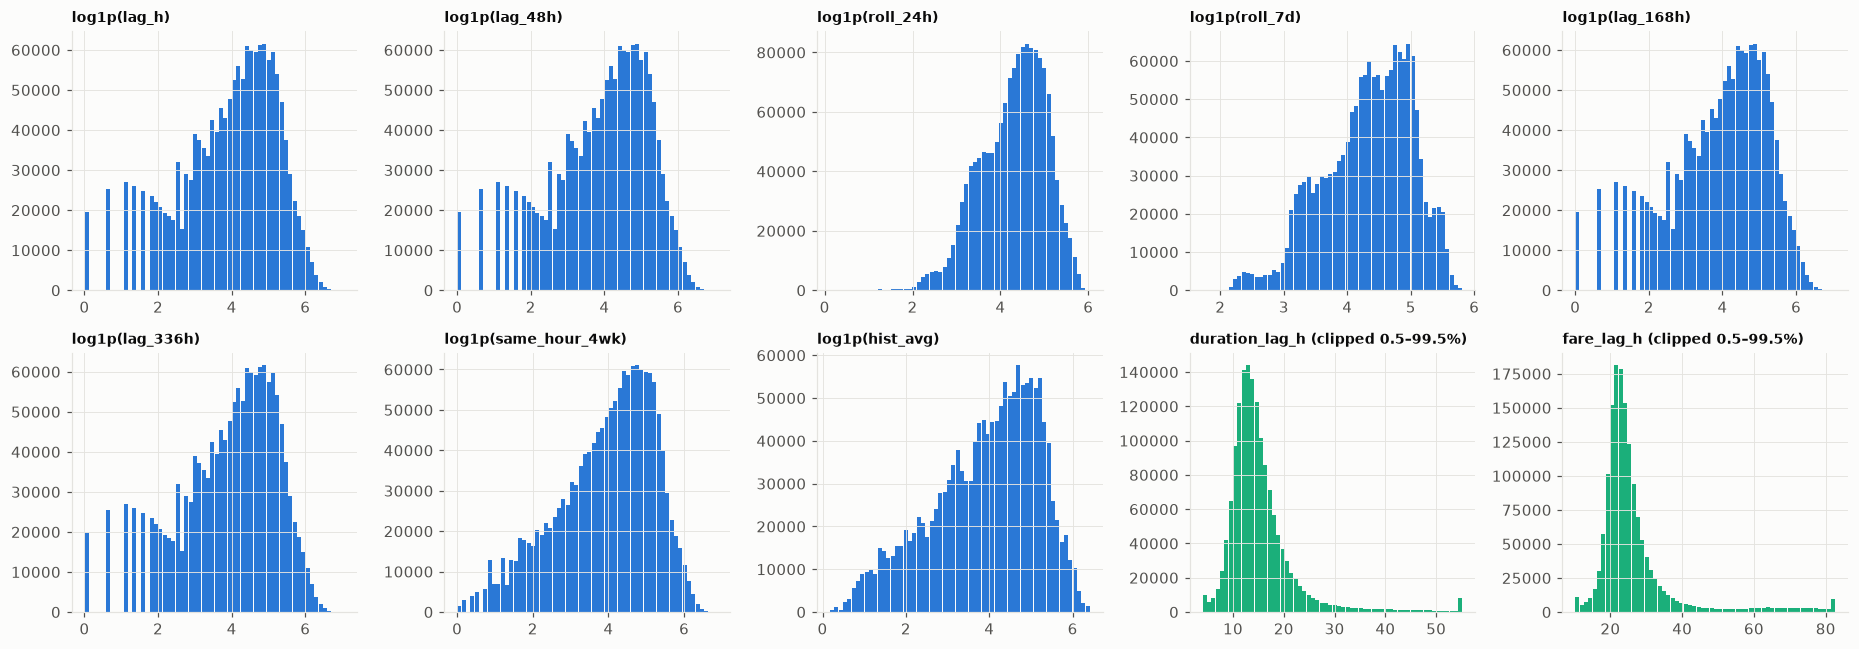

In [18]:
cont = ["lag_h", "lag_48h", "roll_24h", "roll_7d", "lag_168h", "lag_336h", "same_hour_4wk", "hist_avg", "duration_lag_h", "fare_lag_h"]
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, c in zip(axes.flat, cont):
    v = df[c].dropna()
    if c in ("duration_lag_h", "fare_lag_h"):
        lo, hi = v.quantile([.005, .995])
        ax.hist(v.clip(lo, hi), bins=60, color=C[2], rwidth=0.9); ax.set_title(f"{c} (clipped 0.5–99.5%)", fontsize=9)
    else:
        ax.hist(np.log1p(v), bins=60, color=C[0], rwidth=0.9); ax.set_title(f"log1p({c})", fontsize=9)
plt.tight_layout(); plt.show()

duration/fare NaN rate: 1.27%  (NaN exactly when lag_h == 0: True)
avg trip duration > 3h: 425  | negative avg fare: 57  | avg fare > $300: 13


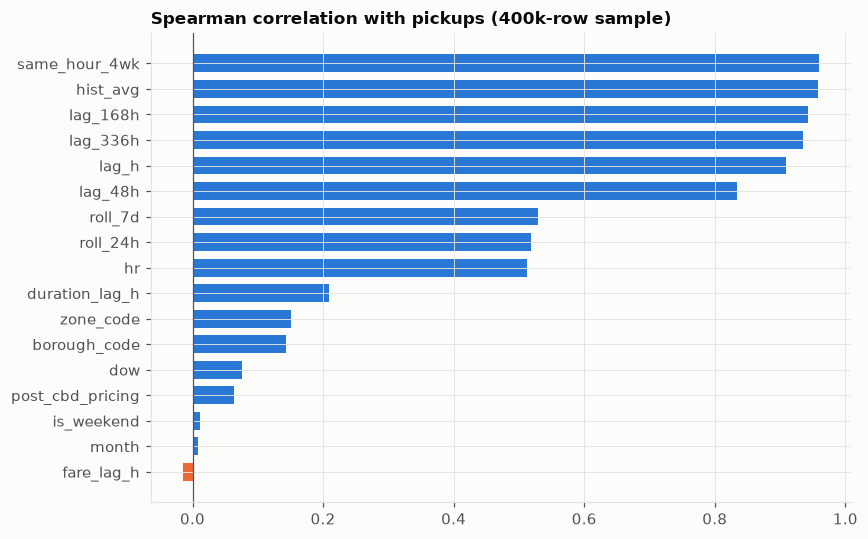

In [19]:
print(f"duration/fare NaN rate: {df.duration_lag_h.isna().mean():.2%}  (NaN exactly when lag_h == 0: "
      f"{bool((df.duration_lag_h.isna() == (df.lag_h == 0)).all())})")
print("avg trip duration > 3h:", (df.duration_lag_h > 180).sum(), " | negative avg fare:", (df.fare_lag_h < 0).sum(),
      " | avg fare > $300:", (df.fare_lag_h > 300).sum())
sample = df.sample(400_000, random_state=0)
corr = sample[FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(corr.index, corr.values, color=[C[0] if v >= 0 else C[1] for v in corr.values], height=0.7)
ax.set_title("Spearman correlation with pickups (400k-row sample)"); ax.axvline(0, color=INK2, linewidth=0.8)
plt.tight_layout(); plt.show()

- The **weekly-pattern features** (`same_hour_4wk`, `hist_avg`, `lag_168h`, ρ ≈ 0.95) carry most of the signal. Next is `lag_h` (yesterday, same hour), then hour of day.
- The demand features are highly collinear. That's fine for tree models; for a GLM, regularize and use them in log space.
- `duration_lag_h` / `fare_lag_h` are rarely missing here (≈ 1%), but still have **raw-data outliers** (cabs that never closed the meter: multi-hour durations; refunds: negative fares). Winsorize them, or use medians in the builder.
- `post_cbd_pricing` is 1 for the whole of val and test, so it acts as a regime/trend marker, not a measurable policy effect.

### 7.2 Is this a Poisson problem?

The target is a count, so the natural fit is a **count model with a log link** (Poisson or negative binomial). The question is whether the variance ≈ the mean, as Poisson assumes, after accounting for zone, weekday, and hour.

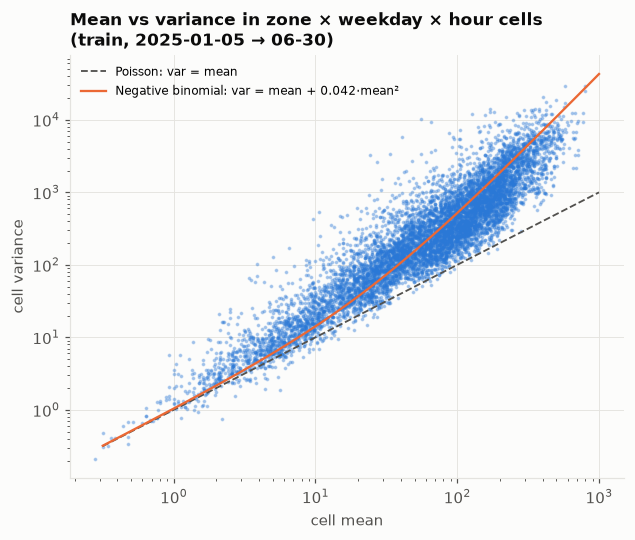

mean
(0, 20]       1.947
(20, 100]     3.427
(100, 2000]   5.738
Name: median var/mean by cell-mean bucket, dtype: float64


In [20]:
recent = df[(df.split == "train") & (df.ts_hour >= SCOPE_START)]
cell = recent.groupby(["zone_id", "dow", "hr"])[TARGET].agg(["mean", "var"]).query("mean > 0")
alpha = np.median(((cell["var"] - cell["mean"]) / cell["mean"] ** 2).clip(lower=0))
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.loglog(cell["mean"], cell["var"], ".", markersize=3, alpha=0.3, color=C[0])
m = np.logspace(-0.5, 3, 50)
ax.plot(m, m, color=INK2, linestyle="--", linewidth=1.2, label="Poisson: var = mean")
ax.plot(m, m + alpha * m ** 2, color=C[1], linewidth=1.5, label=f"Negative binomial: var = mean + {alpha:.3f}·mean²")
ax.set_xlabel("cell mean"); ax.set_ylabel("cell variance"); ax.legend(fontsize=8)
ax.set_title("Mean vs variance in zone × weekday × hour cells\n(train, 2025-01-05 → 06-30)")
plt.show()
print(cell.assign(ratio=cell["var"] / cell["mean"]).groupby(pd.cut(cell["mean"], [0, 20, 100, 2000]), observed=True)
      .ratio.median().rename("median var/mean by cell-mean bucket"))

### 7.3 Benchmarks vs. a first ML model (validation set, Jul–Dec 2025)

- **Business-rule baselines** (what the fleet does today):
  - `lag_168h`: same hour last week
  - `same_hour_4wk`: average of the same hour over the last 4 weeks
  - `hist_avg`: long-run average for that weekday and hour
- **First ML model:** an untuned `HistGradientBoostingRegressor` with Poisson loss, trained on the training split without the data-gap weeks.

**Metrics**
- **WAPE** = Σ|error| / Σ actual. "Out of every 100 trips, how many did we mis-forecast?" Reported pooled across all zones, and per zone so each zone counts equally.
- **MAE**, and **Poisson deviance**, which matches the training loss.

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

gap = df.ts_hour.between("2023-09-21", "2023-10-22 23:00")
tr = df[(df.split == "train") & ~gap]
va = df[df.split == "val"].copy()

def scores(name, pred):
    pred = np.clip(np.asarray(pred, dtype=float), 1e-3, None)
    return {"model": name, "WAPE": np.abs(va[TARGET] - pred).sum() / va[TARGET].sum(),
            "MAE": mean_absolute_error(va[TARGET], pred),
            "Poisson deviance": mean_poisson_deviance(va[TARGET], pred),
            "bias (pred - actual, per zone-hour)": pred.mean() - va[TARGET].mean()}

cat_mask = [c in ("zone_code", "borough_code") for c in FEATURES]
hgb = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                    categorical_features=cat_mask, random_state=0)
hgb.fit(tr[FEATURES], tr[TARGET])
va["hgb"] = hgb.predict(va[FEATURES])

bench = pd.DataFrame([scores(f"rule: {c}", va[c]) for c in ["lag_168h", "same_hour_4wk", "hist_avg"]]
                     + [scores("ML: HGB Poisson", va.hgb)]).set_index("model").sort_values("WAPE")
bench

,WAPE,MAE,Poisson deviance,"bias (pred - actual, per zone-hour)"
model,,,,
ML: HGB Poisson,0.152,15.429,4.866,1.415
rule: same_hour_4wk,0.201,20.391,8.353,1.203
rule: lag_168h,0.226,22.954,11.708,1.452
rule: hist_avg,0.228,23.153,10.132,-10.797


In [22]:
# Per-zone WAPE: every zone on the same relative scale
cols = ["hgb", "same_hour_4wk", "lag_168h"]
zw = va.groupby("zone_name", observed=True).apply(
    lambda g: pd.Series({c: np.abs(g[TARGET] - g[c]).sum() / g[TARGET].sum() for c in cols}), include_groups=False)
ratio = zw.hgb / zw.same_hour_4wk
summary = zw.describe(percentiles=[.1, .5, .9]).T[["10%", "50%", "90%"]].add_prefix("zone WAPE ")
summary["zones where ML beats it"] = [np.nan] + [(zw.hgb < zw[c]).sum() for c in cols[1:]]
print(f"median per-zone improvement of ML vs 4-week rule: {1 - ratio.median():.1%}")
display(summary)

pearson = (va[TARGET] - va.hgb) / np.sqrt(va.hgb.clip(lower=1e-3))
print(f"Pearson dispersion of the Poisson model (1 = Poisson holds): {np.mean(pearson ** 2):.2f}")
by_area = va.groupby("area")[[TARGET, "hgb", "same_hour_4wk", "hist_avg"]].apply(
    lambda g: pd.Series({c: np.abs(g[TARGET] - g[c]).sum() / g[TARGET].sum() for c in ["hgb", "same_hour_4wk", "hist_avg"]}))
by_area.add_prefix("WAPE ")

median per-zone improvement of ML vs 4-week rule: 23.9%


,zone WAPE 10%,zone WAPE 50%,zone WAPE 90%,zones where ML beats it
hgb,0.132,0.157,0.216,NaN
same_hour_4wk,0.177,0.209,0.257,49.000
lag_168h,0.200,0.234,0.302,49.000


Pearson dispersion of the Poisson model (1 = Poisson holds): 5.11


,WAPE hgb,WAPE same_hour_4wk,WAPE hist_avg
area,,,
Airports,0.176,0.209,0.210
Manhattan,0.150,0.200,0.230


**What fits**
- **Variance is well above the mean, and grows like mean + α·mean².** That's the **negative-binomial** pattern (cell var/mean ≈ 3–6; Pearson dispersion of the Poisson model ≈ 5).
  - For **point forecasts** (cabs per zone-hour), a **Poisson-loss gradient-boosted model** is a sound choice: the predicted mean stays unbiased even when the data is over-dispersed.
  - For **ranges and staffing buffers** ("plan for the 80th percentile"), use a **negative binomial** or **quantile** model. Poisson intervals would be far too narrow.
- **No zero-inflation model is needed** (≈ 1% zeros).
- **The untuned ML model already beats every business rule.** Pooled WAPE drops from about 20% (4-week rule) to about **15%**, and it improves on the rule in every one of the 49 zones (median zone ≈ 24% better).
- The long-run average `hist_avg` is the weakest rule: it lags the 2023→2025 growth.
- **Model ladder for the project:** business rules → Poisson/NB GLM → LightGBM/HistGB (Poisson/Tweedie) → add holiday, weather, and event features (the biggest remaining misses; see `residual_check.ipynb`).

## 8. Does it matter? Simulated cost of forecast error for MetroCab Fleet

We turn forecast accuracy into dollars with a deliberately simple, transparent **cost model**. Every assumption is listed and can be changed.

- MetroCab serves a fixed **share** of yellow-cab pickups in each zone-hour. It plans `cabs = forecast × share / trips_per_cab_hour`.
- **Under-forecast** (actual > forecast): the missing trips are lost. Cost = lost trips × share × **average fare** × the fleet's **revenue share**.
- **Over-forecast** (forecast > actual): extra cabs sit idle. Cost = idle cab-hours × **idle cost per cab-hour** (fuel, wear, and the earnings the driver loses, which shows up as driver churn).
- The average fare and trips per cab-hour come from the data. The other inputs are assumptions.

In [23]:
fare = raw.sql(f"""SELECT SUM(avg_fare_total * pickups) / SUM(pickups) AS avg_fare,
                            SUM(avg_duration_min * pickups) / SUM(pickups) AS avg_trip_min
                     FROM panel WHERE ts_hour >= '2025-07-01' AND ts_hour < '2026-01-01'
                       AND zone_id IN ({', '.join(map(str, core.index))})""").df().iloc[0]

ASSUME = {
    "fleet share of pickups": 0.07,                   # ~1,000 of 13,587 medallions
    "avg fare per trip ($, from data)": round(float(fare.avg_fare), 2),
    "avg trip length (min, from data)": round(float(fare.avg_trip_min), 1),
    "trips per cab-hour": 2.0,                        # ~17-min trip + time to find the next fare
    "fleet revenue share of fare": 0.35,              # lease + fees the fleet keeps, vs. driver's take
    "idle cost per cab-hour ($)": 30.0,               # fuel + wear + driver opportunity cost
}
pd.Series(ASSUME, name="assumption").to_frame()

,assumption
fleet share of pickups,0.070
"avg fare per trip ($, from data)",27.200
"avg trip length (min, from data)",17.300
trips per cab-hour,2.000
fleet revenue share of fare,0.350
idle cost per cab-hour ($),30.000


In [24]:
def fleet_cost(actual, forecast, a=ASSUME):
    s = a["fleet share of pickups"]
    under = np.clip(actual - forecast, 0, None) * s                      # trips the fleet missed
    over = np.clip(forecast - actual, 0, None) * s / a["trips per cab-hour"]   # idle cab-hours
    lost = under.sum() * a["avg fare per trip ($, from data)"] * a["fleet revenue share of fare"]
    idle = over.sum() * a["idle cost per cab-hour ($)"]
    return pd.Series({"missed trips": under.sum(), "idle cab-hours": over.sum(),
                      "lost fleet revenue ($)": lost, "idle cost ($)": idle, "total cost ($)": lost + idle})

years = (va.ts_hour.max() - va.ts_hour.min()).days / 365.25
impact = pd.DataFrame({name: fleet_cost(va[TARGET], va[col]) / years for name, col in
                       [("rule: same hour last week", "lag_168h"), ("rule: 4-week average", "same_hour_4wk"),
                        ("rule: long-run average", "hist_avg"), ("ML: HGB Poisson", "hgb")]}).T
impact["savings vs. 4-week rule ($/yr)"] = impact.loc["rule: 4-week average", "total cost ($)"] - impact["total cost ($)"]
print(f"Annualized from the validation period ({years:.2f} years), 49 zones:")
impact.round(0)

Annualized from the validation period (0.50 years), 49 zones:


,missed trips,idle cab-hours,lost fleet revenue ($),idle cost ($),total cost ($),savings vs. 4-week rule ($/yr)
rule: same hour last week,"325,027.000","184,456.000","3,094,255.000","5,533,683.000","8,627,938.000","-970,680.000"
rule: 4-week average,"290,033.000","163,205.000","2,761,111.000","4,896,147.000","7,657,258.000",0.000
rule: long-run average,"513,183.000","93,390.000","4,885,497.000","2,801,697.000","7,687,195.000","-29,937.000"
ML: HGB Poisson,"211,839.000","127,305.000","2,016,705.000","3,819,154.000","5,835,859.000","1,821,399.000"


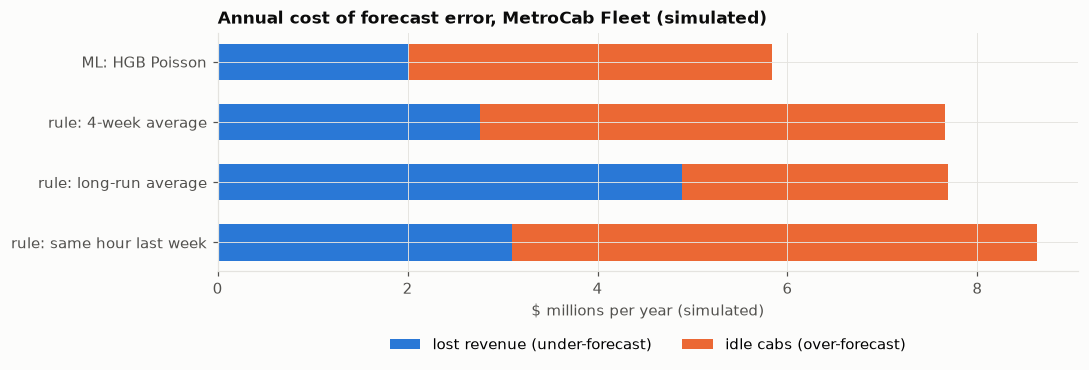

In [25]:
fig, ax = plt.subplots(figsize=(10, 3.6))
order = impact.sort_values("total cost ($)").index
y_pos = np.arange(len(order))
ax.barh(y_pos, impact.loc[order, "lost fleet revenue ($)"] / 1e6, color=C[0], height=0.6, label="lost revenue (under-forecast)")
ax.barh(y_pos, impact.loc[order, "idle cost ($)"] / 1e6, left=impact.loc[order, "lost fleet revenue ($)"] / 1e6,
        color=C[1], height=0.6, label="idle cabs (over-forecast)")
ax.set_yticks(y_pos, order); ax.invert_yaxis()
ax.set_xlabel("$ millions per year (simulated)"); ax.set_title("Annual cost of forecast error, MetroCab Fleet (simulated)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.tight_layout(); plt.show()

In [26]:
# Sensitivity: savings of the ML model vs. the 4-week rule under different assumptions
rows = []
for share in [0.03, 0.07, 0.15]:
    for idle in [20, 30, 45]:
        a = {**ASSUME, "fleet share of pickups": share, "idle cost per cab-hour ($)": idle}
        base = fleet_cost(va[TARGET], va.same_hour_4wk, a)["total cost ($)"] / years
        ml = fleet_cost(va[TARGET], va.hgb, a)["total cost ($)"] / years
        rows.append({"fleet share": share, "idle $/cab-h": idle, "4-week rule cost": base, "ML cost": ml,
                     "savings ($/yr)": base - ml, "savings (%)": (base - ml) / base})
sens = pd.DataFrame(rows).pivot(index="fleet share", columns="idle $/cab-h", values="savings ($/yr)")
print("Annual savings of the ML model vs. the 4-week rule ($/yr):")
sens.round(0)

Annual savings of the ML model vs. the 4-week rule ($/yr):


idle $/cab-h,20,30,45
fleet share,,,
0.030,"626,743.000","780,600.000","1,011,384.000"
0.070,"1,462,401.000","1,821,399.000","2,359,896.000"
0.150,"3,133,717.000","3,902,998.000","5,056,919.000"


**Reading the simulation**
- **Base case:** the 4-week rule costs MetroCab about **$7.7M/yr** in lost revenue plus idle cabs. The untuned ML model cuts that to about **$5.8M/yr**, saving **≈ $1.8M/yr (≈ 24%)**, mostly from fewer idle cab-hours and about 27% fewer missed trips.
- **Same-hour-last-week is the worst rule** (≈ $8.6M/yr). The long-run average misses the most trips because it lags the growth.
- **Sensitivity:** savings range from **≈ $0.6M/yr** (3% fleet share, $20 idle cost) to **≈ $5.1M/yr** (15% share, $45 idle cost). They're positive in every scenario.
- **Caveats (to state in the pitch):**
  1. `pickups` is *served* demand. Truly unmet demand isn't observed, so lost revenue is approximate.
  2. Real fleets can't move cabs instantly, so not every forecast error is avoidable.
  3. The costs are asymmetric (a lost fare ≠ an idle hour). The best plan is therefore a **quantile** of the forecast, not the mean (a newsvendor problem). That's a natural next step that also uses the negative-binomial finding above.

## 9. Flags and next steps

| # | flag | impact | action |
|---|---|---|---|
| 1 | **Scope**: yellow cabs only, 49 busy zones (Manhattan + JFK + LGA, ≈ 93% of yellow pickups) | conclusions are about yellow-cab demand in Manhattan and at the airports, not all NYC ride demand | state this in the pitch; `data/core_zones.csv` has the zone list |
| 2 | **Served ≠ total demand**: unmet riders aren't recorded | under-states demand when cabs are scarce | acknowledge; busy zones are rarely supply-constrained |
| 3 | **Regime shift**: some zones grew 1.4–2.3× from 2023 to 2025 | long-run averages lag; old data mis-calibrates | recency weights or a shorter window; rolling-origin backtests |
| 4 | **`hist_avg`** spans both regimes and includes each training row's own target | lags in val/test; flatters training fit | trailing-window version, or leave-one-out in train |
| 5 | **Data gap 2023-09-21 → 24** recorded as zero pickups | fake zeros, plus 4 weeks of corrupted lags | drop 2023-09-21 → 10-22 from training |
| 6 | **Holidays / weather / events** not in the features | the largest remaining errors | add a holiday calendar, a weather feed, an event schedule |
| 7 | **`post_cbd_pricing`** = 1 throughout val/test | not a measurable policy effect | treat as a regime marker |
| 8 | **DST hours** | a few large errors per year | flag/exclude in evaluation |
| 9 | Trip-context outliers (multi-hour durations, negative fares) | noisy features | winsorize or use medians |
| 10 | Val (Jul–Dec) vs test (Jan–Aug) cover different seasons | error levels not comparable | rolling-origin CV; refit on train+val for test |

In [32]:
df

,zone_id,zone_name,borough,ts_hour,split,pickups,zone_code,borough_code,lag_h,lag_48h,roll_24h,roll_7d,lag_168h,lag_336h,same_hour_4wk,hist_avg,duration_lag_h,fare_lag_h,hr,dow,month,is_weekend,post_cbd_pricing,area
4,13,Battery Park City,Manhattan,2023-01-29 00:00:00,train,3,4,2,8,4,24.250,23.655,6,2,7.000,8.786,189.500,22.450,0,0,1,1,0,Manhattan
13,41,Central Harlem,Manhattan,2023-01-29 00:00:00,train,9,13,2,5,7,11.750,9.827,4,6,9.750,15.908,275.600,17.420,0,0,1,1,0,Manhattan
15,43,Central Park,Manhattan,2023-01-29 00:00:00,train,13,15,2,18,9,80.958,69.589,20,21,38.500,20.237,11.170,23.230,0,0,1,1,0,Manhattan
17,48,Clinton East,Manhattan,2023-01-29 00:00:00,train,255,17,2,238,134,130.708,115.125,272,255,220.750,264.183,12.280,23.260,0,0,1,1,0,Manhattan
19,50,Clinton West,Manhattan,2023-01-29 00:00:00,train,53,19,2,34,11,28.792,25.048,50,42,51.500,51.420,10.590,22.010,0,0,1,1,0,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3523959,246,West Chelsea/Hudson Yards,Manhattan,2026-08-31 23:00:00,test,19,103,2,41,76,78.625,76.548,22,24,28.250,31.740,16.100,26.400,23,1,8,0,1,Manhattan
3523961,249,West Village,Manhattan,2026-08-31 23:00:00,test,100,105,2,78,448,123.750,98.548,94,86,81.250,87.786,13.010,23.700,23,1,8,0,1,Manhattan
3523965,261,World Trade Center,Manhattan,2026-08-31 23:00:00,test,9,109,2,9,24,22.375,22.714,5,10,7.750,7.794,11.780,33.720,23,1,8,0,1,Manhattan
3523966,262,Yorkville East,Manhattan,2026-08-31 23:00:00,test,14,110,2,10,29,45.458,61.488,7,11,10.000,8.557,13.400,28.320,23,1,8,0,1,Manhattan
